In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project


In [4]:
from src.config import (
    DATA_DIR,
    IMAGE_DIR,
    METADATA_PATH,
    GROUND_TRUTH_PATH,
)

In [13]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    DATA_DIR,
    IMAGE_DIR,
    METADATA_PATH,
    GROUND_TRUTH_PATH,
    SPLIT_DIR,
    FIGURE_DIR,
    REPORT_DIR,
    ARTIFACT_DIR,
)

print("Setup complete.")
print("Project root:", PROJECT_ROOT)
print("Artifact directory:", ARTIFACT_DIR)

Setup complete.
Project root: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project
Artifact directory: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\artifacts


In [6]:
metadata = pd.read_csv(METADATA_PATH)
ground_truth = pd.read_csv(GROUND_TRUTH_PATH)

print("Metadata shape:", metadata.shape)
print("Ground-truth shape:", ground_truth.shape)

print("\nMetadata columns:")
print(metadata.columns.tolist())

print("\nGround-truth columns:")
print(ground_truth.columns.tolist())

Metadata shape: (10480, 17)
Ground-truth shape: (5240, 12)

Metadata columns:
['isic_id', 'attribution', 'copyright_license', 'age_approx', 'anatom_site_general', 'anatom_site_special', 'concomitant_biopsy', 'diagnosis_1', 'diagnosis_2', 'diagnosis_3', 'diagnosis_4', 'diagnosis_confirm_type', 'image_manipulation', 'image_type', 'lesion_id', 'melanocytic', 'sex']

Ground-truth columns:
['lesion_id', 'AKIEC', 'BCC', 'BEN_OTH', 'BKL', 'DF', 'INF', 'MAL_OTH', 'MEL', 'NV', 'SCCKA', 'VASC']


In [7]:
print("Unique image IDs:", metadata["isic_id"].nunique())
print("Metadata rows:", len(metadata))

print("Unique metadata lesions:", metadata["lesion_id"].nunique())
print("Ground-truth lesions:", ground_truth["lesion_id"].nunique())

print(
    "Duplicate image IDs:",
    metadata["isic_id"].duplicated().sum()
)

print(
    "Duplicate ground-truth lesion IDs:",
    ground_truth["lesion_id"].duplicated().sum()
)

Unique image IDs: 10480
Metadata rows: 10480
Unique metadata lesions: 5240
Ground-truth lesions: 5240
Duplicate image IDs: 0
Duplicate ground-truth lesion IDs: 0


In [8]:
images_per_lesion = metadata.groupby("lesion_id").size()

print(images_per_lesion.value_counts())

print(
    "All lesions have exactly 2 images:",
    (images_per_lesion == 2).all()
)

2    5240
Name: count, dtype: int64
All lesions have exactly 2 images: True


In [9]:
image_types_per_lesion = (
    metadata
    .groupby("lesion_id")["image_type"]
    .apply(lambda x: sorted(x.tolist()))
)

print(image_types_per_lesion.value_counts())

image_type
[clinical: close-up, dermoscopic]    5240
Name: count, dtype: int64


In [10]:
expected_types = {"clinical: close-up", "dermoscopic"}

all_have_both_types = all(
    set(types) == expected_types
    for types in image_types_per_lesion
)

print(
    "Every lesion has both image types:",
    all_have_both_types
)

Every lesion has both image types: True


In [11]:
# Ground-truth ↔ metadata linkage
metadata_lesions = set(metadata["lesion_id"])
ground_truth_lesions = set(ground_truth["lesion_id"])

metadata_missing_gt = metadata_lesions - ground_truth_lesions
gt_missing_metadata = ground_truth_lesions - metadata_lesions

print("Metadata lesions missing ground truth:", len(metadata_missing_gt))
print("Ground-truth lesions missing metadata:", len(gt_missing_metadata))


# Ground-truth label consistency
label_columns = [
    "AKIEC", "BCC", "BEN_OTH", "BKL", "DF",
    "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"
]

positive_labels_per_lesion = ground_truth[label_columns].sum(axis=1)

print(
    "\nPositive labels per lesion:"
)
print(positive_labels_per_lesion.value_counts().sort_index())

print(
    "Every lesion has exactly one label:",
    (positive_labels_per_lesion == 1).all()
)


# Check image files on disk
image_files = list(IMAGE_DIR.glob("*.jpg"))

file_ids = {path.stem for path in image_files}
metadata_ids = set(metadata["isic_id"])

missing_files = metadata_ids - file_ids
unexpected_files = file_ids - metadata_ids

print("\nJPEG files found:", len(image_files))
print("Metadata images missing on disk:", len(missing_files))
print("Unexpected image files:", len(unexpected_files))

Metadata lesions missing ground truth: 0
Ground-truth lesions missing metadata: 0

Positive labels per lesion:
1    5240
Name: count, dtype: int64
Every lesion has exactly one label: True

JPEG files found: 10480
Metadata images missing on disk: 0
Unexpected image files: 0


In [14]:
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

integrity_checks = pd.DataFrame([
    ["Metadata rows", len(metadata), len(metadata) == 10480],
    ["Unique image IDs", metadata["isic_id"].nunique(), metadata["isic_id"].nunique() == 10480],
    ["Unique lesions", metadata["lesion_id"].nunique(), metadata["lesion_id"].nunique() == 5240],
    ["Ground-truth lesions", ground_truth["lesion_id"].nunique(), ground_truth["lesion_id"].nunique() == 5240],
    ["Duplicate image IDs", metadata["isic_id"].duplicated().sum(), metadata["isic_id"].duplicated().sum() == 0],
    ["Duplicate GT lesion IDs", ground_truth["lesion_id"].duplicated().sum(), ground_truth["lesion_id"].duplicated().sum() == 0],
    ["All lesions have 2 images", int((images_per_lesion == 2).all()), (images_per_lesion == 2).all()],
    ["All lesions have both image types", int(all_have_both_types), all_have_both_types],
    ["Metadata lesions missing GT", len(metadata_missing_gt), len(metadata_missing_gt) == 0],
    ["GT lesions missing metadata", len(gt_missing_metadata), len(gt_missing_metadata) == 0],
    ["All lesions have one label", int((positive_labels_per_lesion == 1).all()), (positive_labels_per_lesion == 1).all()],
    ["JPEG files", len(image_files), len(image_files) == 10480],
    ["Missing image files", len(missing_files), len(missing_files) == 0],
    ["Unexpected image files", len(unexpected_files), len(unexpected_files) == 0],
], columns=["check", "value", "passed"])

integrity_checks.to_csv(
    ARTIFACT_DIR / "dataset_integrity_audit.csv",
    index=False
)

print(integrity_checks)
print("\n✅ B1 COMPLETE")

                                check  value  passed
0                       Metadata rows  10480    True
1                    Unique image IDs  10480    True
2                      Unique lesions   5240    True
3                Ground-truth lesions   5240    True
4                 Duplicate image IDs      0    True
5             Duplicate GT lesion IDs      0    True
6           All lesions have 2 images      1    True
7   All lesions have both image types      1    True
8         Metadata lesions missing GT      0    True
9         GT lesions missing metadata      0    True
10         All lesions have one label      1    True
11                         JPEG files  10480    True
12                Missing image files      0    True
13             Unexpected image files      0    True

✅ B1 COMPLETE


In [15]:
import matplotlib.pyplot as plt

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

label
BCC        2522
NV          746
BKL         544
SCCKA       473
MEL         450
AKIEC       303
DF           52
INF          50
VASC         47
BEN_OTH      44
MAL_OTH       9
Name: count, dtype: int64


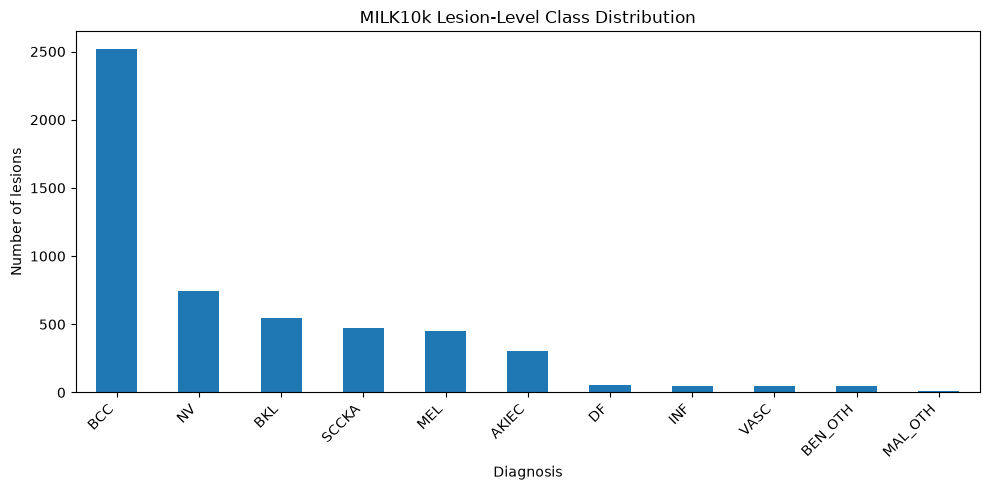

In [16]:
# Convert one-hot ground truth into a single lesion-level label
ground_truth["label"] = ground_truth[label_columns].idxmax(axis=1)

class_counts = (
    ground_truth["label"]
    .value_counts()
    .sort_values(ascending=False)
)

print(class_counts)

plt.figure(figsize=(10, 5))
class_counts.plot(kind="bar")

plt.title("MILK10k Lesion-Level Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of lesions")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

image_type
dermoscopic           5240
clinical: close-up    5240
Name: count, dtype: int64


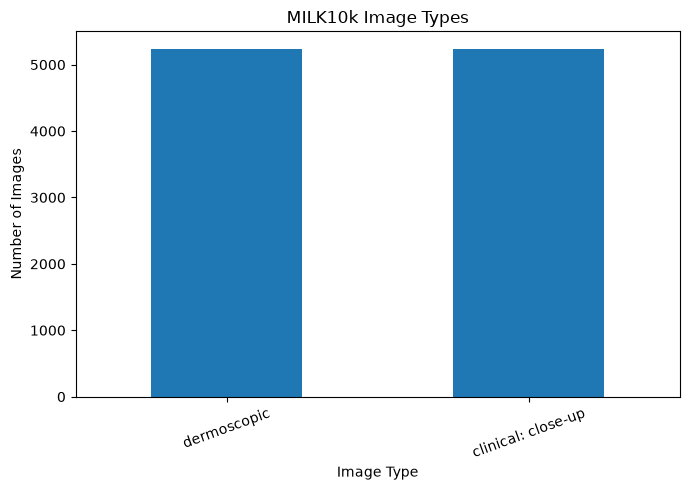

In [17]:
image_type_counts = metadata["image_type"].value_counts()

print(image_type_counts)

plt.figure(figsize=(7, 5))
image_type_counts.plot(kind="bar")

plt.title("MILK10k Image Types")
plt.xlabel("Image Type")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "image_type_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

count    10440.000000
mean        61.355364
std         15.691646
min          5.000000
25%         50.000000
50%         65.000000
75%         75.000000
max         85.000000
Name: age_approx, dtype: float64


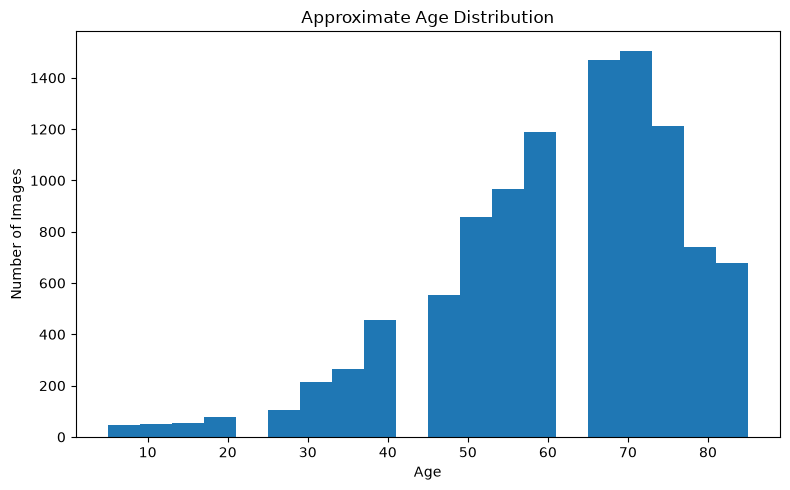

In [18]:
age = metadata["age_approx"].dropna()

print(age.describe())

plt.figure(figsize=(8, 5))
age.plot(
    kind="hist",
    bins=20
)

plt.title("Approximate Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "age_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

sex
male      6304
female    4176
Name: count, dtype: int64


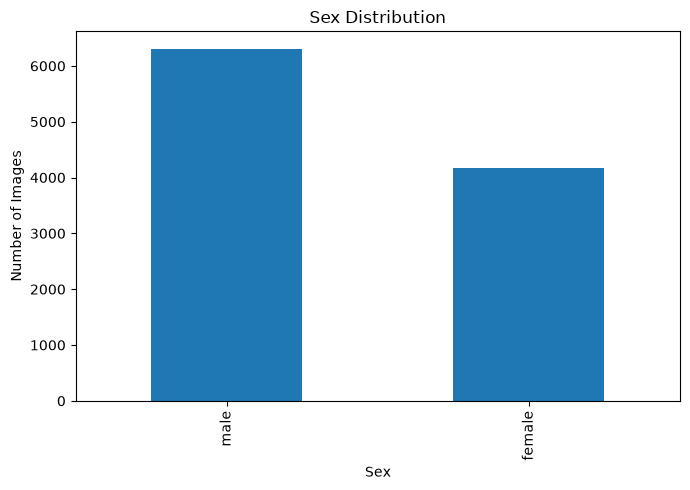

In [19]:
sex_counts = metadata["sex"].value_counts(dropna=False)

print(sex_counts)

plt.figure(figsize=(7, 5))
sex_counts.plot(kind="bar")

plt.title("Sex Distribution")
plt.xlabel("Sex")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "sex_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

anatom_site_general
NaN                3912
head/neck          2982
lower extremity    2092
upper extremity    1478
oral/genital         16
Name: count, dtype: int64


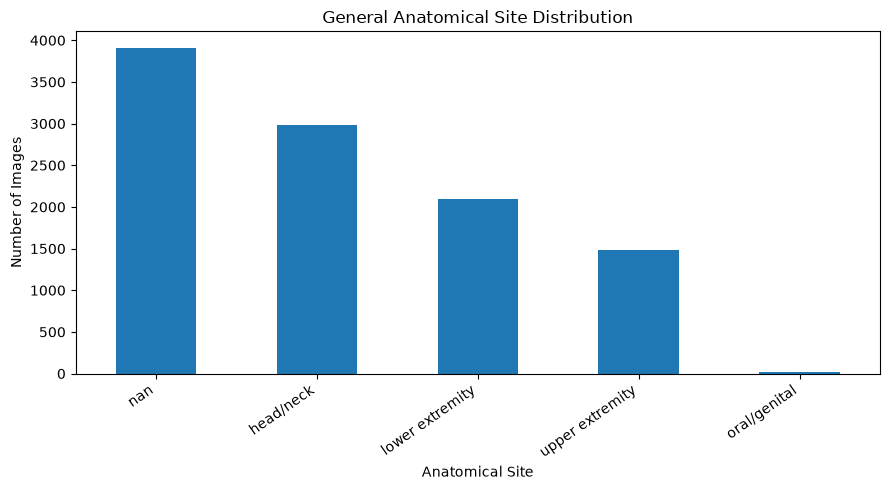

In [20]:
site_counts = metadata["anatom_site_general"].value_counts(dropna=False)

print(site_counts)

plt.figure(figsize=(9, 5))
site_counts.plot(kind="bar")

plt.title("General Anatomical Site Distribution")
plt.xlabel("Anatomical Site")
plt.ylabel("Number of Images")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "anatomical_site_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

anatom_site_special    10274
diagnosis_4             8958
melanocytic             8088
anatom_site_general     3912
diagnosis_3              158
age_approx                40
dtype: int64


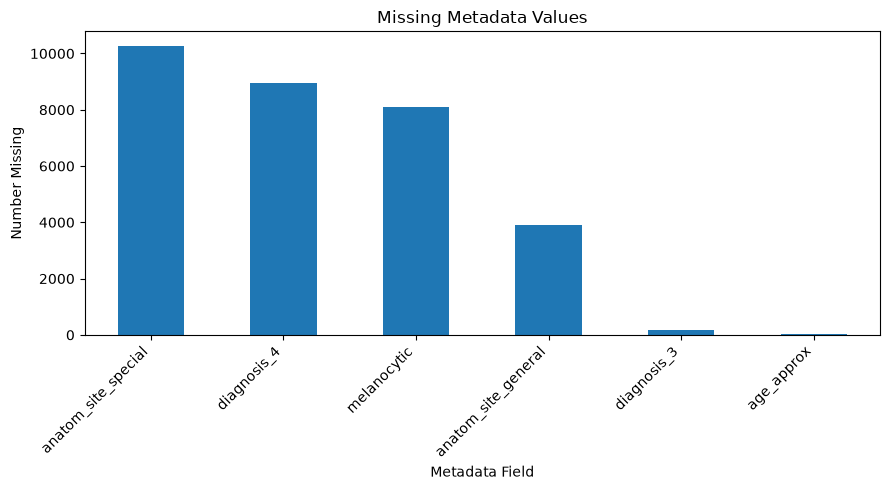

In [21]:
missingness = (
    metadata.isna()
    .sum()
    .sort_values(ascending=False)
)

missingness = missingness[missingness > 0]

print(missingness)

plt.figure(figsize=(9, 5))
missingness.plot(kind="bar")

plt.title("Missing Metadata Values")
plt.xlabel("Metadata Field")
plt.ylabel("Number Missing")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "metadata_missingness.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [22]:
eda_summary = pd.DataFrame({
    "class": class_counts.index,
    "lesion_count": class_counts.values,
})

eda_summary.to_csv(
    ARTIFACT_DIR / "class_distribution.csv",
    index=False
)

print("Saved EDA artifacts.")
print("Figures saved to:", FIGURE_DIR)

Saved EDA artifacts.
Figures saved to: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\figures


In [23]:
# B3: Define the 11-class label and create the lesion-level table

label_columns = [
    "AKIEC", "BCC", "BEN_OTH", "BKL", "DF",
    "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"
]

# One-hot ground truth -> single class label
ground_truth["label"] = ground_truth[label_columns].idxmax(axis=1)

# Check that every lesion has exactly one positive class
positive_counts = ground_truth[label_columns].sum(axis=1)
assert (positive_counts == 1).all()

lesion_labels = ground_truth[["lesion_id", "label"]].copy()

# One row per lesion with both image IDs
image_table = (
    metadata[["lesion_id", "isic_id", "image_type"]]
    .pivot(
        index="lesion_id",
        columns="image_type",
        values="isic_id"
    )
    .reset_index()
)

image_table = image_table.rename(columns={
    "dermoscopic": "dermoscopic_isic_id",
    "clinical: close-up": "clinical_isic_id"
})

lesion_table = lesion_labels.merge(
    image_table,
    on="lesion_id",
    how="left"
)

assert len(lesion_table) == 5240
assert lesion_table["label"].notna().all()
assert lesion_table["clinical_isic_id"].notna().all()
assert lesion_table["dermoscopic_isic_id"].notna().all()

lesion_table.to_csv(
    ARTIFACT_DIR / "lesion_table.csv",
    index=False
)

print("Lesion table shape:", lesion_table.shape)
print("\nClass counts:")
print(lesion_table["label"].value_counts().sort_values(ascending=False))
print("\nSaved:", ARTIFACT_DIR / "lesion_table.csv")

Lesion table shape: (5240, 4)

Class counts:
label
BCC        2522
NV          746
BKL         544
SCCKA       473
MEL         450
AKIEC       303
DF           52
INF          50
VASC         47
BEN_OTH      44
MAL_OTH       9
Name: count, dtype: int64

Saved: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\artifacts\lesion_table.csv


In [24]:
# B4: Image quality report

from PIL import Image
import os

quality_rows = []

image_ids = metadata["isic_id"].tolist()

for i, image_id in enumerate(image_ids, start=1):
    image_path = IMAGE_DIR / f"{image_id}.jpg"

    with Image.open(image_path) as img:
        rgb = img.convert("RGB")
        arr = np.asarray(rgb, dtype=np.float32)

        width, height = rgb.size

        quality_rows.append({
            "isic_id": image_id,
            "width": width,
            "height": height,
            "mean_pixel": float(arr.mean()),
            "std_pixel": float(arr.std()),
            "file_size_bytes": os.path.getsize(image_path),
        })

    if i % 1000 == 0:
        print(f"Processed {i}/{len(image_ids)} images")

quality_report = pd.DataFrame(quality_rows)

quality_report.to_csv(
    ARTIFACT_DIR / "image_quality_report.csv",
    index=False
)

print("\nQuality report shape:", quality_report.shape)

print("\nImage dimensions:")
print(
    quality_report[["width", "height"]]
    .value_counts()
    .head(10)
)

print("\nQuality statistics:")
print(
    quality_report[
        ["width", "height", "mean_pixel", "std_pixel", "file_size_bytes"]
    ].describe()
)

print("\nSaved:", ARTIFACT_DIR / "image_quality_report.csv")

Processed 1000/10480 images
Processed 2000/10480 images
Processed 3000/10480 images
Processed 4000/10480 images
Processed 5000/10480 images
Processed 6000/10480 images
Processed 7000/10480 images
Processed 8000/10480 images
Processed 9000/10480 images
Processed 10000/10480 images

Quality report shape: (10480, 6)

Image dimensions:
width  height
600    450       10480
Name: count, dtype: int64

Quality statistics:
         width   height    mean_pixel     std_pixel  file_size_bytes
count  10480.0  10480.0  10480.000000  10480.000000     10480.000000
mean     600.0    450.0    142.916475     34.779625     33839.778531
std        0.0      0.0     20.900272     10.867630     10505.902963
min      600.0    450.0     36.554092      6.682956     11822.000000
25%      600.0    450.0    128.441196     27.064048     25729.500000
50%      600.0    450.0    142.160027     34.294292     32172.500000
75%      600.0    450.0    156.837276     41.378035     40691.000000
max      600.0    450.0    235

In [25]:
# B4 summary checks

print("Number of unique image dimensions:",
      quality_report[["width", "height"]].drop_duplicates().shape[0])

print("Minimum file size:",
      quality_report["file_size_bytes"].min(), "bytes")

print("Maximum file size:",
      quality_report["file_size_bytes"].max(), "bytes")

print("Minimum mean pixel value:",
      quality_report["mean_pixel"].min())

print("Maximum mean pixel value:",
      quality_report["mean_pixel"].max())

print("\nMissing values:")
print(quality_report.isna().sum())

Number of unique image dimensions: 1
Minimum file size: 11822 bytes
Maximum file size: 101478 bytes
Minimum mean pixel value: 36.55409240722656
Maximum mean pixel value: 235.6088104248047

Missing values:
isic_id            0
width              0
height             0
mean_pixel         0
std_pixel          0
file_size_bytes    0
dtype: int64


In [26]:
# B5: Reusable lesion-level split function

from sklearn.model_selection import train_test_split

def make_lesion_split(
    df,
    lesion_col="lesion_id",
    label_col="label",
    test_size=0.20,
    val_size=0.20,
    random_state=42,
):
    lesion_df = df[[lesion_col, label_col]].drop_duplicates()

    label_counts = lesion_df.groupby(lesion_col)[label_col].nunique()

    if not (label_counts == 1).all():
        raise ValueError(
            "Each lesion must have exactly one unique label."
        )

    train_lesions, temp_lesions = train_test_split(
        lesion_df,
        test_size=test_size + val_size,
        random_state=random_state,
        stratify=lesion_df[label_col],
    )

    val_fraction_of_temp = val_size / (test_size + val_size)

    val_lesions, test_lesions = train_test_split(
        temp_lesions,
        test_size=1 - val_fraction_of_temp,
        random_state=random_state,
        stratify=temp_lesions[label_col],
    )

    train_ids = set(train_lesions[lesion_col])
    val_ids = set(val_lesions[lesion_col])
    test_ids = set(test_lesions[lesion_col])

    train = df[df[lesion_col].isin(train_ids)].copy()
    val = df[df[lesion_col].isin(val_ids)].copy()
    test = df[df[lesion_col].isin(test_ids)].copy()

    return train, val, test

In [27]:
# Create image-level rows with lesion-level labels
image_level = metadata[
    ["isic_id", "lesion_id", "image_type"]
].merge(
    lesion_labels,
    on="lesion_id",
    how="left"
)

train_split, val_split, test_split = make_lesion_split(
    image_level,
    lesion_col="lesion_id",
    label_col="label",
    test_size=0.20,
    val_size=0.20,
    random_state=42,
)

# Verify there is no lesion leakage
train_lesions = set(train_split["lesion_id"])
val_lesions = set(val_split["lesion_id"])
test_lesions = set(test_split["lesion_id"])

assert train_lesions.isdisjoint(val_lesions)
assert train_lesions.isdisjoint(test_lesions)
assert val_lesions.isdisjoint(test_lesions)

# Every original image appears exactly once
original_ids = set(image_level["isic_id"])
split_ids = (
    set(train_split["isic_id"])
    | set(val_split["isic_id"])
    | set(test_split["isic_id"])
)

assert original_ids == split_ids

assert len(set(train_split["isic_id"]) & set(val_split["isic_id"])) == 0
assert len(set(train_split["isic_id"]) & set(test_split["isic_id"])) == 0
assert len(set(val_split["isic_id"]) & set(test_split["isic_id"])) == 0

print("Train:", train_split.shape)
print("Val:  ", val_split.shape)
print("Test: ", test_split.shape)

print("\nUnique lesions:")
print("Train:", train_split["lesion_id"].nunique())
print("Val:  ", val_split["lesion_id"].nunique())
print("Test: ", test_split["lesion_id"].nunique())

print("\nClass distribution by split:")
for name, split in [
    ("train", train_split),
    ("val", val_split),
    ("test", test_split),
]:
    print(f"\n{name}")
    print(split["label"].value_counts().sort_index())

Train: (6288, 4)
Val:   (2096, 4)
Test:  (2096, 4)

Unique lesions:
Train: 3144
Val:   1048
Test:  1048

Class distribution by split:

train
label
AKIEC       364
BCC        3026
BEN_OTH      54
BKL         652
DF           62
INF          60
MAL_OTH      10
MEL         540
NV          896
SCCKA       568
VASC         56
Name: count, dtype: int64

val
label
AKIEC       122
BCC        1010
BEN_OTH      16
BKL         218
DF           20
INF          20
MAL_OTH       4
MEL         180
NV          298
SCCKA       188
VASC         20
Name: count, dtype: int64

test
label
AKIEC       120
BCC        1008
BEN_OTH      18
BKL         218
DF           22
INF          20
MAL_OTH       4
MEL         180
NV          298
SCCKA       190
VASC         18
Name: count, dtype: int64


In [28]:
# Save final split CSVs

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

train_split.to_csv(SPLIT_DIR / "train.csv", index=False)
val_split.to_csv(SPLIT_DIR / "val.csv", index=False)
test_split.to_csv(SPLIT_DIR / "test.csv", index=False)

print("\nSaved:")
print(SPLIT_DIR / "train.csv")
print(SPLIT_DIR / "val.csv")
print(SPLIT_DIR / "test.csv")


Saved:
C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\splits\train.csv
C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\splits\val.csv
C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\splits\test.csv


In [30]:
# B6: Define image preprocessing and transformations

import torch
from torchvision import transforms

IMAGE_SIZE = (224, 224)

# ImageNet normalization parameters
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

# Training transformations with conservative augmentation
train_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.15,
        hue=0.03
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

# Deterministic transformations for validation and testing
eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Training transformations defined.")
print("Evaluation transformations defined.")

Training transformations defined.
Evaluation transformations defined.


In [31]:
# Test preprocessing using a real dataset image

from PIL import Image

sample_id = metadata.iloc[0]["isic_id"]
sample_path = IMAGE_DIR / f"{sample_id}.jpg"

with Image.open(sample_path) as img:
    sample_image = img.convert("RGB")

    train_tensor = train_transform(sample_image)

    eval_tensor_1 = eval_transform(sample_image)
    eval_tensor_2 = eval_transform(sample_image)

# Verify tensor dimensions
assert train_tensor.shape == (3, 224, 224)
assert eval_tensor_1.shape == (3, 224, 224)

# Verify data type
assert train_tensor.dtype == torch.float32
assert eval_tensor_1.dtype == torch.float32

# Verify deterministic evaluation preprocessing
assert torch.equal(eval_tensor_1, eval_tensor_2)

# Verify that the tensors contain no invalid values
assert torch.isfinite(train_tensor).all()
assert torch.isfinite(eval_tensor_1).all()

print("Sample image ID:", sample_id)
print("Training tensor shape:", train_tensor.shape)
print("Evaluation tensor shape:", eval_tensor_1.shape)
print("Tensor data type:", eval_tensor_1.dtype)
print("Evaluation preprocessing is deterministic.")
print("All B6 checks passed!")

Sample image ID: ISIC_0051817
Training tensor shape: torch.Size([3, 224, 224])
Evaluation tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32
Evaluation preprocessing is deterministic.
All B6 checks passed!


In [32]:
# B7: Create a consistent mapping from class labels to integer indices

label_names = sorted(lesion_labels["label"].unique())

label_to_idx = {
    label: idx
    for idx, label in enumerate(label_names)
}

idx_to_label = {
    idx: label
    for label, idx in label_to_idx.items()
}

print("Number of classes:", len(label_names))
print("\nLabel mapping:")

for label, idx in label_to_idx.items():
    print(f"{label}: {idx}")

assert len(label_to_idx) == 11

print("\nB7.1 checks passed!")

Number of classes: 11

Label mapping:
AKIEC: 0
BCC: 1
BEN_OTH: 2
BKL: 3
DF: 4
INF: 5
MAL_OTH: 6
MEL: 7
NV: 8
SCCKA: 9
VASC: 10

B7.1 checks passed!


In [33]:
# B7: Implement the PyTorch Dataset

from torch.utils.data import Dataset
from PIL import Image

class LesionDataset(Dataset):
    def __init__(
        self,
        df,
        image_dir,
        transform=None,
        label_to_idx=None
    ):
        self.df = df.reset_index(drop=True).copy()
        self.image_dir = image_dir
        self.transform = transform
        self.label_to_idx = label_to_idx

        if self.label_to_idx is None:
            labels = sorted(self.df["label"].unique())
            self.label_to_idx = {
                label: idx
                for idx, label in enumerate(labels)
            }

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = self.image_dir / f"{row['isic_id']}.jpg"

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform is not None:
            image = self.transform(image)

        label = self.label_to_idx[row["label"]]

        return {
            "image": image,
            "label": torch.tensor(label, dtype=torch.long),
            "lesion_id": row["lesion_id"],
            "isic_id": row["isic_id"],
        }

print("LesionDataset class defined successfully.")

LesionDataset class defined successfully.


In [34]:
# Create the three datasets

train_dataset = LesionDataset(
    df=train_split,
    image_dir=IMAGE_DIR,
    transform=train_transform,
    label_to_idx=label_to_idx
)

val_dataset = LesionDataset(
    df=val_split,
    image_dir=IMAGE_DIR,
    transform=eval_transform,
    label_to_idx=label_to_idx
)

test_dataset = LesionDataset(
    df=test_split,
    image_dir=IMAGE_DIR,
    transform=eval_transform,
    label_to_idx=label_to_idx
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

assert len(train_dataset) == len(train_split)
assert len(val_dataset) == len(val_split)
assert len(test_dataset) == len(test_split)

print("\nB7.3 checks passed!")

Training images: 6288
Validation images: 2096
Test images: 2096

B7.3 checks passed!


In [35]:
# Create DataLoaders

from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 197
Validation batches: 66
Test batches: 66


In [36]:
# Inspect one batch from the training DataLoader

batch = next(iter(train_loader))

print("Image batch shape:", batch["image"].shape)
print("Label batch shape:", batch["label"].shape)
print("Image tensor dtype:", batch["image"].dtype)
print("Label tensor dtype:", batch["label"].dtype)
print("First five labels:", batch["label"][:5].tolist())
print("First five lesion IDs:", batch["lesion_id"][:5])

assert batch["image"].shape[1:] == (3, 224, 224)
assert batch["label"].dtype == torch.long
assert batch["label"].min() >= 0
assert batch["label"].max() < len(label_to_idx)

print("\nAll B7 checks passed!")

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image tensor dtype: torch.float32
Label tensor dtype: torch.int64
First five labels: [1, 1, 1, 9, 0]
First five lesion IDs: ['IL_0758607', 'IL_8375905', 'IL_5283078', 'IL_8497763', 'IL_0583192']

All B7 checks passed!


In [37]:
# B8.1: Calculate class weights using the training split

import numpy as np
import pandas as pd
import torch

from sklearn.utils.class_weight import compute_class_weight

# Count training images in each class
train_class_counts = (
    train_split["label"]
    .value_counts()
    .reindex(label_names, fill_value=0)
)

print("Training class counts:")
print(train_class_counts)

# Calculate balanced class weights
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.array(label_names),
    y=train_split["label"].to_numpy()
)

class_weights = torch.tensor(
    class_weights_array,
    dtype=torch.float32
)

class_weight_map = dict(zip(label_names, class_weights_array))

print("\nClass weights:")
for label, weight in class_weight_map.items():
    print(f"{label}: {weight:.4f}")

assert len(class_weights) == len(label_names)
assert torch.isfinite(class_weights).all()
assert (class_weights > 0).all()

print("\nB8.1 checks passed!")

Training class counts:
label
AKIEC       364
BCC        3026
BEN_OTH      54
BKL         652
DF           62
INF          60
MAL_OTH      10
MEL         540
NV          896
SCCKA       568
VASC         56
Name: count, dtype: int64

Class weights:
AKIEC: 1.5704
BCC: 0.1889
BEN_OTH: 10.5859
BKL: 0.8767
DF: 9.2199
INF: 9.5273
MAL_OTH: 57.1636
MEL: 1.0586
NV: 0.6380
SCCKA: 1.0064
VASC: 10.2078

B8.1 checks passed!


In [38]:
# B8.2: Assign a sampling weight to every training image

sample_weights = train_split["label"].map(
    class_weight_map
).to_numpy()

sample_weights = torch.as_tensor(
    sample_weights,
    dtype=torch.double
)

assert len(sample_weights) == len(train_dataset)
assert torch.isfinite(sample_weights).all()
assert (sample_weights > 0).all()

print("Number of sample weights:", len(sample_weights))
print("Minimum sample weight:", sample_weights.min().item())
print("Maximum sample weight:", sample_weights.max().item())

print("\nB8.2 checks passed!")

Number of sample weights: 6288
Minimum sample weight: 0.18890824971459472
Maximum sample weight: 57.163636363636364

B8.2 checks passed!


C:\Users\Kinjal Chatterjee\AppData\Local\Temp\ipykernel_25628\2653975511.py:7: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  sample_weights = torch.as_tensor(


In [39]:
# B8.3: Create a WeightedRandomSampler

from torch.utils.data import WeightedRandomSampler

train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True,
    generator=torch.Generator().manual_seed(42)
)

print("WeightedRandomSampler created.")
print("Samples drawn per training epoch:", len(train_sampler))

WeightedRandomSampler created.
Samples drawn per training epoch: 6288


In [40]:
# B8.4: Recreate the DataLoaders using the weighted sampler

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

print("\nB8.4 checks passed!")

Training batches: 197
Validation batches: 66
Test batches: 66

B8.4 checks passed!


In [41]:
# B8.5: Inspect class frequencies produced by the sampler

sampled_indices = list(iter(train_sampler))

sampled_labels = (
    train_split.iloc[sampled_indices]["label"]
    .value_counts()
    .reindex(label_names, fill_value=0)
)

sampling_summary = pd.DataFrame({
    "original_count": train_class_counts,
    "sampled_count": sampled_labels
})

sampling_summary["original_proportion"] = (
    sampling_summary["original_count"]
    / sampling_summary["original_count"].sum()
)

sampling_summary["sampled_proportion"] = (
    sampling_summary["sampled_count"]
    / sampling_summary["sampled_count"].sum()
)

print(sampling_summary.round(4))

print("\nOriginal class proportion range:",
      round(sampling_summary["original_proportion"].min(), 4),
      "to",
      round(sampling_summary["original_proportion"].max(), 4))

print("Sampled class proportion range:",
      round(sampling_summary["sampled_proportion"].min(), 4),
      "to",
      round(sampling_summary["sampled_proportion"].max(), 4))

         original_count  sampled_count  original_proportion  \
label                                                         
AKIEC               364            621               0.0579   
BCC                3026            572               0.4812   
BEN_OTH              54            576               0.0086   
BKL                 652            548               0.1037   
DF                   62            520               0.0099   
INF                  60            583               0.0095   
MAL_OTH              10            571               0.0016   
MEL                 540            575               0.0859   
NV                  896            614               0.1425   
SCCKA               568            564               0.0903   
VASC                 56            544               0.0089   

         sampled_proportion  
label                        
AKIEC                0.0988  
BCC                  0.0910  
BEN_OTH              0.0916  
BKL                  0.0872  


In [42]:
# B9.1: Verify dataset and split integrity

# Expected dataset sizes
assert len(metadata) == 10480
assert len(ground_truth) == 5240
assert len(lesion_table) == 5240

# Every image ID should be unique
assert metadata["isic_id"].is_unique

# Every lesion must have exactly two images
images_per_lesion = metadata.groupby("lesion_id").size()
assert (images_per_lesion == 2).all()

# Every split must contain exactly two images per lesion
for name, split in [
    ("Train", train_split),
    ("Validation", val_split),
    ("Test", test_split),
]:
    assert (split.groupby("lesion_id").size() == 2).all()
    print(f"{name}: {len(split)} images, "
          f"{split['lesion_id'].nunique()} lesions")

# Check for lesion leakage
train_ids = set(train_split["lesion_id"])
val_ids = set(val_split["lesion_id"])
test_ids = set(test_split["lesion_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

# Every image must appear in exactly one split
all_split_images = (
    list(train_split["isic_id"])
    + list(val_split["isic_id"])
    + list(test_split["isic_id"])
)

assert len(all_split_images) == len(set(all_split_images))
assert set(all_split_images) == set(metadata["isic_id"])

print("\nB9.1 passed: dataset integrity and split isolation verified.")

Train: 6288 images, 3144 lesions
Validation: 2096 images, 1048 lesions
Test: 2096 images, 1048 lesions

B9.1 passed: dataset integrity and split isolation verified.


In [43]:
# B9.2: Verify label mapping and class coverage

assert len(label_to_idx) == 11
assert len(idx_to_label) == 11

assert set(label_to_idx.keys()) == set(label_names)

for label, idx in label_to_idx.items():
    assert idx_to_label[idx] == label

for name, split in [
    ("Train", train_split),
    ("Validation", val_split),
    ("Test", test_split),
]:
    unknown_labels = set(split["label"]) - set(label_to_idx)
    assert not unknown_labels, f"{name} contains unknown labels."

    print(f"{name}: {split['label'].nunique()} classes present")

print("\nB9.2 passed: label mapping is consistent.")

Train: 11 classes present
Validation: 11 classes present
Test: 11 classes present

B9.2 passed: label mapping is consistent.


In [44]:
# B9.3: Verify batch shapes, data types, and values

batch = next(iter(train_loader))

images = batch["image"]
labels = batch["label"]

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)

assert images.ndim == 4
assert images.shape[1:] == (3, 224, 224)
assert labels.ndim == 1
assert images.shape[0] == labels.shape[0]

assert images.dtype == torch.float32
assert labels.dtype == torch.long

assert torch.isfinite(images).all()
assert torch.isfinite(labels).all()

assert labels.min().item() >= 0
assert labels.max().item() < len(label_to_idx)

assert len(batch["lesion_id"]) == len(labels)
assert len(batch["isic_id"]) == len(labels)

print("\nB9.3 passed: DataLoader batch is valid.")

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64

B9.3 passed: DataLoader batch is valid.


In [45]:
# B9.4: Confirm repeated evaluation preprocessing gives identical results

from PIL import Image
import torch

sample_id = val_split.iloc[0]["isic_id"]
sample_path = IMAGE_DIR / f"{sample_id}.jpg"

with Image.open(sample_path) as img:
    sample_image = img.convert("RGB")

    eval_1 = eval_transform(sample_image)
    eval_2 = eval_transform(sample_image)

assert torch.equal(eval_1, eval_2)
assert eval_1.shape == (3, 224, 224)
assert torch.isfinite(eval_1).all()

print("Evaluation transform is deterministic.")
print("Tensor shape:", eval_1.shape)
print("\nB9.4 passed.")

Evaluation transform is deterministic.
Tensor shape: torch.Size([3, 224, 224])

B9.4 passed.


In [46]:
# B9.5: Verify sampler configuration and weights

assert len(sample_weights) == len(train_dataset)
assert len(train_sampler) == len(train_dataset)

assert torch.isfinite(sample_weights).all()
assert (sample_weights > 0).all()

assert train_loader.sampler is train_sampler
assert val_loader.sampler is not train_sampler
assert test_loader.sampler is not train_sampler

print("Training sampler:", type(train_loader.sampler).__name__)
print("Validation sampler:", type(val_loader.sampler).__name__)
print("Test sampler:", type(test_loader.sampler).__name__)

print("\nB9.5 passed: sampler configuration is valid.")

Training sampler: WeightedRandomSampler
Validation sampler: SequentialSampler
Test sampler: SequentialSampler

B9.5 passed: sampler configuration is valid.


In [47]:
# B9.6: Save pipeline sanity-check summary

from pathlib import Path

sanity_results = {
    "metadata_rows": len(metadata),
    "ground_truth_rows": len(ground_truth),
    "unique_images": metadata["isic_id"].nunique(),
    "unique_lesions": metadata["lesion_id"].nunique(),
    "number_of_classes": len(label_names),
    "train_images": len(train_split),
    "val_images": len(val_split),
    "test_images": len(test_split),
    "train_lesions": train_split["lesion_id"].nunique(),
    "val_lesions": val_split["lesion_id"].nunique(),
    "test_lesions": test_split["lesion_id"].nunique(),
    "batch_size": BATCH_SIZE,
    "image_height": IMAGE_SIZE[0],
    "image_width": IMAGE_SIZE[1],
    "lesion_leakage": False,
    "evaluation_transforms_deterministic": True,
    "weighted_sampler_configured": True,
    "all_assertions_passed": True,
}

sanity_df = pd.DataFrame(
    list(sanity_results.items()),
    columns=["check", "result"]
)

sanity_path = ARTIFACT_DIR / "pipeline_sanity_checks.csv"
sanity_df.to_csv(sanity_path, index=False)

print(sanity_df.to_string(index=False))
print("\nSaved:", sanity_path)

                              check result
                      metadata_rows  10480
                  ground_truth_rows   5240
                      unique_images  10480
                     unique_lesions   5240
                  number_of_classes     11
                       train_images   6288
                         val_images   2096
                        test_images   2096
                      train_lesions   3144
                        val_lesions   1048
                       test_lesions   1048
                         batch_size     32
                       image_height    224
                        image_width    224
                     lesion_leakage  False
evaluation_transforms_deterministic   True
        weighted_sampler_configured   True
              all_assertions_passed   True

Saved: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\artifacts\pipeline_sanity_checks.csv


In [48]:
# B10: Create the milestone report

report_text = """
# MILK10k Computer Vision Project
## Milestone 1 Report

### 1. Dataset and Problem Definition

MILK10k contains 10,480 dermoscopic and clinical close-up images representing
5,240 unique lesions. Each lesion has exactly two associated images: one
dermoscopic image and one clinical close-up image. The diagnostic target is an
11-class classification problem using the labels AKIEC, BCC, BEN_OTH, BKL, DF,
INF, MAL_OTH, MEL, NV, SCCKA, and VASC.

The dataset is substantially imbalanced. BCC is the largest class, while
MAL_OTH, BEN_OTH, VASC, INF, and DF are much smaller. Because multiple images
belong to the same lesion, lesion identity must be treated as the grouping
unit throughout dataset splitting and evaluation.

### 2. Dataset Integrity and Exploratory Analysis

The integrity audit found 10,480 unique image IDs and 5,240 unique lesion IDs.
Every lesion has exactly two images, with one dermoscopic image and one clinical
close-up. All ground-truth lesions could be linked to metadata, and every
lesion had exactly one positive diagnostic label. All 10,480 expected JPEG
files were present, with no missing or unexpected image files.

Metadata analysis showed variation in age, sex, anatomical site, image
manipulation, and diagnostic confirmation type. Missing metadata was retained
rather than being treated as an image-level failure. Image quality statistics
were collected for width, height, mean pixel intensity, pixel standard
deviation, and file size and saved as a reproducible artifact.

The class distribution and key metadata distributions were visualized and
saved under the figures directory.

### 3. Label Strategy and Data Splitting

The one-hot ground-truth representation was converted into a single
11-class diagnostic label for each lesion. A lesion-level table was created
containing the lesion ID, diagnostic label, dermoscopic image ID, and clinical
image ID.

The final train, validation, and test sets were created at the lesion level
using stratification by diagnostic class. This prevents the two images from
the same lesion from appearing in different splits. The resulting split
contains approximately 60% of lesions for training and 20% each for validation
and testing, corresponding to approximately 6,288 training images, 2,096
validation images, and 2,096 test images.

No lesion overlap exists between the three splits, and all original images are
assigned to exactly one split. The split CSV files are stored in the splits
directory.

### 4. Preprocessing and Augmentation

Images are resized to 224 × 224 pixels, converted to RGB tensors, and
normalized using ImageNet channel statistics. Training images use conservative
augmentation consisting of horizontal flipping, small rotations, and mild
brightness and hue adjustments.

Large color or brightness changes were avoided because pigmentation,
erythema, and skin tone can contain clinically relevant information. Validation
and test images use deterministic resizing, tensor conversion, and
normalization without random augmentation.

Repeated application of the evaluation transform to the same image produced
identical tensors, confirming deterministic evaluation preprocessing.

### 5. PyTorch Data Pipeline

A custom PyTorch Dataset was implemented to load images from disk, apply the
appropriate transformation, convert diagnostic labels to integer class
indices, and return image IDs and lesion IDs alongside the image and label.

Separate DataLoaders were created for training, validation, and testing.
Training uses a weighted sampler to address class imbalance, while validation
and test sets are not resampled.

Balanced class weights were calculated from the training set only. These
weights were assigned to individual training samples and used to construct a
WeightedRandomSampler with replacement. Inspection of the sampled distribution
confirmed that the sampler increases the representation of underrepresented
classes.

### 6. Validation and Reproducibility

Pipeline sanity checks verified dataset sizes, image and lesion uniqueness,
class mappings, split isolation, tensor dimensions, numerical validity,
evaluation determinism, and sampler configuration.

All raw images remain outside the repository and are excluded through
.gitignore. Reproducible split CSV files, figures, quality reports, and
sanity-check artifacts are stored in the repository. The project uses a fixed
random seed of 42 for reproducible splitting and sampling.

### 7. Limitations and Next Steps

The main limitation at this milestone is the strong class imbalance,
particularly for the rare diagnostic categories. The dataset also contains
two images per lesion, making lesion-level grouping essential to prevent
information leakage.

No predictive model is trained or evaluated in this milestone. The completed
work establishes a leakage-safe dataset, preprocessing pipeline, class
balancing strategy, and reproducible PyTorch data pipeline. The next stage
will use this infrastructure for model training and lesion-level evaluation.
"""

report_path = REPORT_DIR / "milestone_report.md"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

report_path.write_text(
    report_text.strip(),
    encoding="utf-8"
)

print("Milestone report saved to:")
print(report_path)

Milestone report saved to:
C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\reports\milestone_report.md


In [49]:
# Verify the milestone report exists

assert report_path.exists()
assert report_path.stat().st_size > 0

print("Report exists:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")

print("\nReport preview:\n")
print(report_text[:2000])

Report exists: C:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\reports\milestone_report.md
Report size: 5134 bytes

Report preview:


# MILK10k Computer Vision Project
## Milestone 1 Report

### 1. Dataset and Problem Definition

MILK10k contains 10,480 dermoscopic and clinical close-up images representing
5,240 unique lesions. Each lesion has exactly two associated images: one
dermoscopic image and one clinical close-up image. The diagnostic target is an
11-class classification problem using the labels AKIEC, BCC, BEN_OTH, BKL, DF,
INF, MAL_OTH, MEL, NV, SCCKA, and VASC.

The dataset is substantially imbalanced. BCC is the largest class, while
MAL_OTH, BEN_OTH, VASC, INF, and DF are much smaller. Because multiple images
belong to the same lesion, lesion identity must be treated as the grouping
unit throughout dataset splitting and evaluation.

### 2. Dataset Integrity and Exploratory Analysis

The integrity audit found 10,480 unique image IDs and 5,240 unique lesion IDs.
Every lesi